# Mini Project 2: Handwritten Digit Classifier

**Goal:** train a **fully connected neural network** on the MNIST dataset to recognize handwritten digits 0 to 9.

| Required feature | Where it is in this notebook |
|---|---|
| Predict digits from 0-9 | Steps 3 to 5 |
| Display sample predictions | Step 7 |
| Report test accuracy and a confusion matrix | Step 6 |
| Show at least five incorrect predictions and discuss reasons | Steps 8 and 9 |

**Notes**
- The first run downloads MNIST (about 11 MB), so you need an internet connection. The data is saved in a `mnist_data` folder in your home folder, not in this project.
- A fully connected network treats the image as 784 separate numbers (28 x 28 pixels, flattened). It has no built-in idea of shapes or neighbouring pixels,
  and that matters in the error analysis.

## Step 1: Imports and setup

In [1]:
import os
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

DATA_DIR = os.path.join(os.path.expanduser("~"), "mnist_data")
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


## Step 2: Load MNIST and split it

- 60,000 training images become **54,000 train + 6,000 validation**.
- The separate **10,000 test images** are only used once, at the end.
- Pixels are scaled and normalized with the standard MNIST mean (0.1307) and standard deviation (0.3081).


0.3%


0.7%


1.0%


1.3%


1.7%

...


97.4%


99.4%


100.0%


100.0%

Train: 54000 | Validation: 6000 | Test: 10000


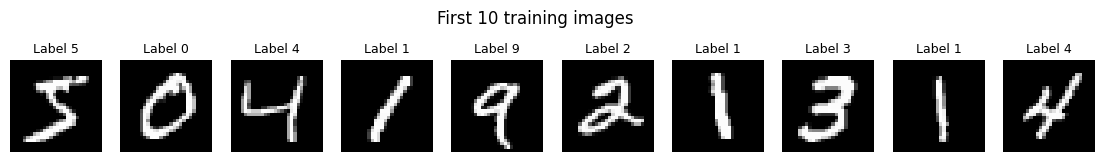

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

train_full = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
test_ds = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)

train_ds, val_ds = random_split(train_full, [54000, 6000], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=256)
test_loader = DataLoader(test_ds, batch_size=256)   # not shuffled, so row i matches test_ds[i]

print("Train:", len(train_ds), "| Validation:", len(val_ds), "| Test:", len(test_ds))

# A first look at the data
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for ax, i in zip(axes, range(10)):
    ax.imshow(train_full.data[i].numpy(), cmap="gray")
    ax.set_title(f"Label {int(train_full.targets[i])}", fontsize=9)
    ax.axis("off")
plt.suptitle("First 10 training images")
plt.show()

## Step 3: Build the fully connected network

`784 inputs -> 256 neurons (ReLU) -> 128 neurons (ReLU) -> 10 outputs`

The 10 outputs are one score per digit. Dropout randomly switches off 20% of neurons during training to reduce overfitting.
`CrossEntropyLoss` is the multiclass loss function: it applies softmax to the scores internally and compares them with the true digit.

In [3]:
model = nn.Sequential(
    nn.Flatten(),                      # 28 x 28 image -> 784 numbers
    nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(128, 10),                # one score per digit 0-9
)
print(model)
print("Total trainable parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=256, out_features=128, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.2, inplace=False)
  (7): Linear(in_features=128, out_features=10, bias=True)
)
Total trainable parameters: 235,146


## Step 4: Train the model

Adam optimizer, learning rate 0.001, batch size 128, 10 epochs. After every epoch we measure validation accuracy
and keep the weights from the **best** epoch.

In [4]:
EPOCHS = 10
LEARNING_RATE = 0.001

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)


def run_epoch(loader, optimizer=None):
    """One pass over the data. Trains if an optimizer is given, otherwise only measures."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            out = model(xb)                       # forward pass
            loss = loss_fn(out, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()                   # backpropagation
                optimizer.step()                  # update the weights
            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            count += xb.size(0)
    return total_loss / count, correct / count


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state = 0.0, None

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, optimizer)
    va_loss, va_acc = run_epoch(val_loader)
    for key, value in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
        history[key].append(value)
    note = ""
    if va_acc > best_val_acc:
        best_val_acc, best_state = va_acc, copy.deepcopy(model.state_dict())
        note = "  <- best so far"
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f}{note}")

model.load_state_dict(best_state)
print(f"\nRestored the best weights (validation accuracy {best_val_acc:.4f})")

Epoch  1/10 | train loss 0.3362 acc 0.8970 | val loss 0.1492 acc 0.9578  <- best so far


Epoch  2/10 | train loss 0.1416 acc 0.9567 | val loss 0.1036 acc 0.9690  <- best so far


Epoch  3/10 | train loss 0.1050 acc 0.9677 | val loss 0.0954 acc 0.9718  <- best so far


Epoch  4/10 | train loss 0.0831 acc 0.9740 | val loss 0.0833 acc 0.9752  <- best so far


Epoch  5/10 | train loss 0.0707 acc 0.9773 | val loss 0.0792 acc 0.9760  <- best so far


Epoch  6/10 | train loss 0.0631 acc 0.9803 | val loss 0.0794 acc 0.9755


Epoch  7/10 | train loss 0.0558 acc 0.9821 | val loss 0.0782 acc 0.9765  <- best so far


Epoch  8/10 | train loss 0.0500 acc 0.9833 | val loss 0.0752 acc 0.9788  <- best so far


Epoch  9/10 | train loss 0.0461 acc 0.9847 | val loss 0.0738 acc 0.9773


Epoch 10/10 | train loss 0.0431 acc 0.9860 | val loss 0.0796 acc 0.9777

Restored the best weights (validation accuracy 0.9788)


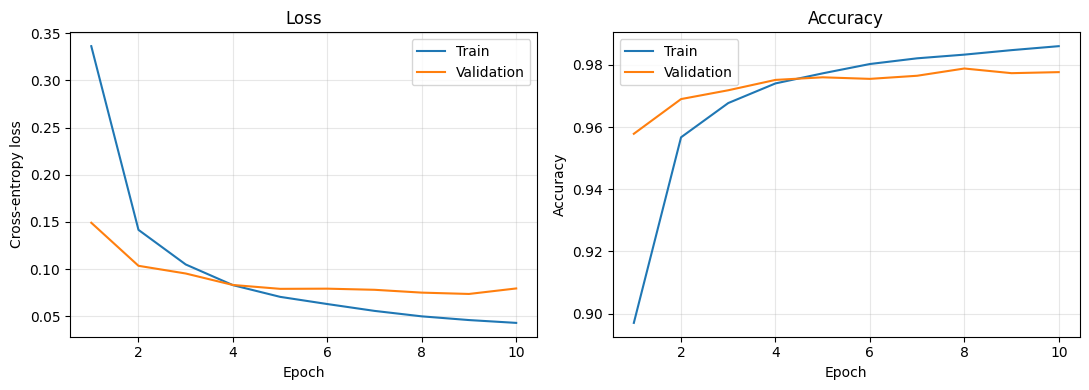

In [5]:
epochs_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs_axis, history["train_loss"], label="Train")
axes[0].plot(epochs_axis, history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[1].plot(epochs_axis, history["train_acc"], label="Train")
axes[1].plot(epochs_axis, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

## Step 5: Predict on the 10,000 test images

For every test image we keep the 10 probabilities, the predicted digit (the largest probability) and the confidence.

In [6]:
model.eval()
all_probs, all_true = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        all_probs.append(torch.softmax(model(xb), dim=1).numpy())
        all_true.append(yb.numpy())

probs = np.concatenate(all_probs)          # shape (10000, 10)
y_true = np.concatenate(all_true)
y_pred = probs.argmax(axis=1)
confidence = probs.max(axis=1)

test_acc = float((y_pred == y_true).mean())
print(f"Test accuracy: {test_acc * 100:.2f}%  ({int((y_pred == y_true).sum())} of {len(y_true)} correct)")

Test accuracy: 97.92%  (9792 of 10000 correct)


## Step 6: Test metrics and confusion matrix

- **Precision** for a digit: of the images the model called that digit, how many really were.
- **Recall** for a digit: of the images that really are that digit, how many the model found.
- **Confusion matrix:** rows are the true digit, columns are the predicted digit. The diagonal holds the correct predictions,
  and every off-diagonal number is a specific kind of mistake.

In [7]:
def confusion_matrix(y_true, y_pred, n_classes=10):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm


def per_class_report(cm):
    diag = np.diag(cm).astype(float)
    predicted_counts = cm.sum(axis=0).astype(float)
    true_counts = cm.sum(axis=1).astype(float)
    precision = np.divide(diag, predicted_counts, out=np.zeros_like(diag), where=predicted_counts > 0)
    recall = np.divide(diag, true_counts, out=np.zeros_like(diag), where=true_counts > 0)
    return precision, recall


def top_confusions(cm, k=5):
    """The k most common mistakes as (count, true digit, predicted digit)."""
    off = cm.copy()
    np.fill_diagonal(off, 0)
    pairs = [(int(off[i, j]), i, j) for i in range(off.shape[0]) for j in range(off.shape[1]) if off[i, j] > 0]
    return sorted(pairs, reverse=True)[:k]

Test accuracy: 97.92%

Digit | Precision | Recall
------+-----------+-------
  0   |   0.977   | 0.994
  1   |   0.996   | 0.989
  2   |   0.973   | 0.985
  3   |   0.979   | 0.977
  4   |   0.979   | 0.969
  5   |   0.969   | 0.985
  6   |   0.986   | 0.982
  7   |   0.983   | 0.979
  8   |   0.975   | 0.965
  9   |   0.970   | 0.965


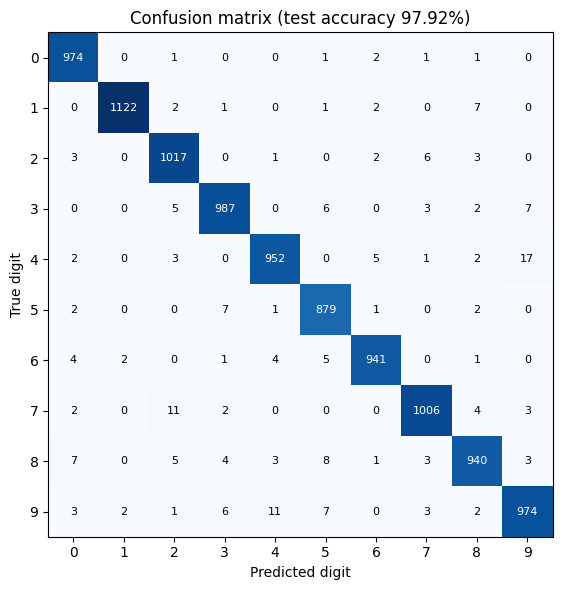

In [8]:
cm = confusion_matrix(y_true, y_pred)
precision, recall = per_class_report(cm)

print(f"Test accuracy: {test_acc * 100:.2f}%\n")
print("Digit | Precision | Recall")
print("------+-----------+-------")
for d in range(10):
    print(f"  {d}   |   {precision[d]:.3f}   | {recall[d]:.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Blues")
ax.set_title(f"Confusion matrix (test accuracy {test_acc * 100:.2f}%)")
ax.set_xlabel("Predicted digit")
ax.set_ylabel("True digit")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

## Step 7: Sample predictions

16 random test images. The title shows the model's prediction, the true digit and the confidence.
**Green** means correct, **red** means wrong.

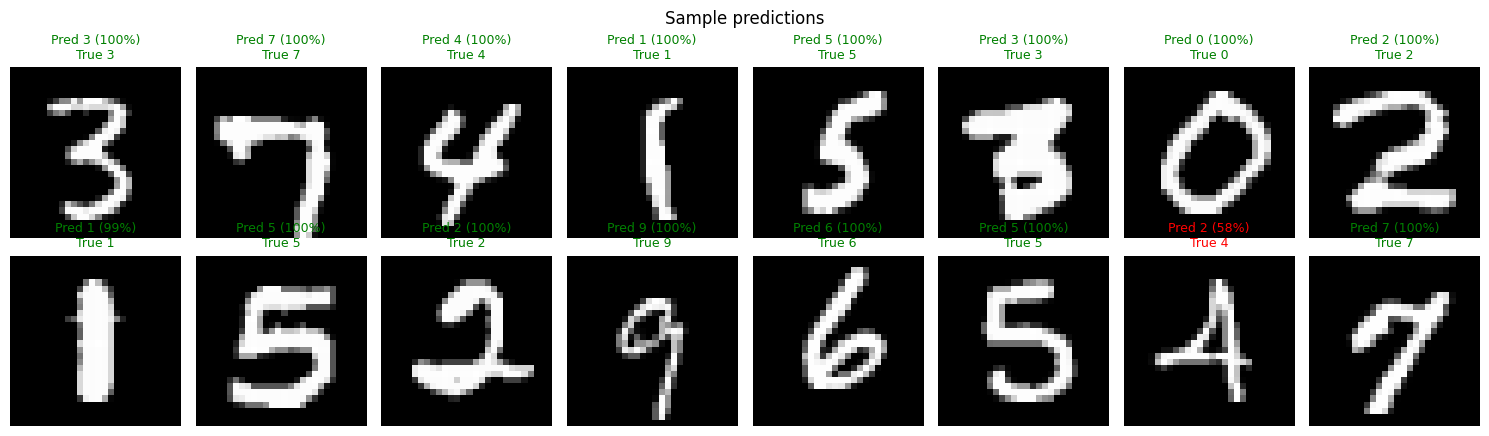

In [9]:
raw_images = test_ds.data.numpy()          # original 28 x 28 pixels, row i matches y_true[i]
rng = np.random.default_rng(0)
sample_idx = rng.choice(len(y_true), size=16, replace=False)

fig, axes = plt.subplots(2, 8, figsize=(15, 4.4))
for ax, i in zip(axes.ravel(), sample_idx):
    ax.imshow(raw_images[i], cmap="gray")
    ok = y_pred[i] == y_true[i]
    ax.set_title(f"Pred {y_pred[i]} ({confidence[i] * 100:.0f}%)\nTrue {y_true[i]}",
                 color="green" if ok else "red", fontsize=9)
    ax.axis("off")
plt.suptitle("Sample predictions")
plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=150)
plt.show()

## Step 8: Incorrect predictions

Here are the mistakes the model was **most confident about**, since those are the most interesting to study.

The model got 208 of 10000 test images wrong.



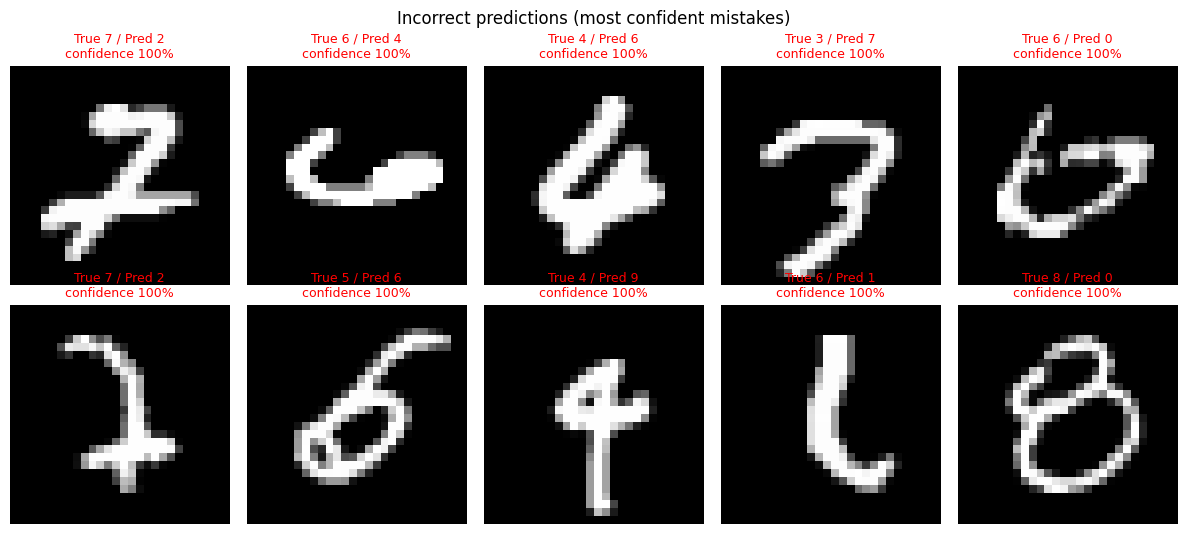

 Image | True | Pred | Confidence |  Probability of the true digit
--------------------------------------------------------------------
  9009 |    7 |    2 |     100.0% |                           0.0%
  3520 |    6 |    4 |     100.0% |                           0.0%
  1112 |    4 |    6 |     100.0% |                           0.0%
  1681 |    3 |    7 |      99.9% |                           0.0%
   445 |    6 |    0 |      99.9% |                           0.1%
  1226 |    7 |    2 |      99.9% |                           0.0%
  9729 |    5 |    6 |      99.9% |                           0.0%
  2053 |    4 |    9 |      99.8% |                           0.2%
  2654 |    6 |    1 |      99.7% |                           0.1%
  1717 |    8 |    0 |      99.6% |                           0.3%


In [10]:
wrong = np.where(y_pred != y_true)[0]
print(f"The model got {len(wrong)} of {len(y_true)} test images wrong.\n")

order = wrong[np.argsort(-confidence[wrong])]     # most confident mistakes first
show = order[:10]

fig, axes = plt.subplots(2, 5, figsize=(12, 5.4))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(raw_images[i], cmap="gray")
    ax.set_title(f"True {y_true[i]} / Pred {y_pred[i]}\nconfidence {confidence[i] * 100:.0f}%", fontsize=9, color="red")
    ax.axis("off")
plt.suptitle("Incorrect predictions (most confident mistakes)")
plt.tight_layout()
plt.savefig("misclassified.png", dpi=150)
plt.show()

print(f"{'Image':>6} | {'True':>4} | {'Pred':>4} | {'Confidence':>10} | {'Probability of the true digit':>30}")
print("-" * 68)
for i in show:
    print(f"{i:>6} | {y_true[i]:>4} | {y_pred[i]:>4} | {confidence[i] * 100:>9.1f}% | {probs[i, y_true[i]] * 100:>29.1f}%")

## Step 9: Error analysis

In [11]:
print("Most common mistakes (true digit -> predicted digit):")
for count, t, p in top_confusions(cm, k=6):
    print(f"  {t} -> {p}: {count} times")

top2 = (np.argsort(-probs[wrong], axis=1)[:, :2] == y_true[wrong][:, None]).any(axis=1)
print(f"\nIn {top2.mean() * 100:.0f}% of the wrong predictions, the correct digit was the model's second choice.")
print(f"Average confidence on wrong predictions:   {confidence[wrong].mean() * 100:.1f}%")
print(f"Average confidence on correct predictions: {confidence[y_pred == y_true].mean() * 100:.1f}%")

Most common mistakes (true digit -> predicted digit):
  4 -> 9: 17 times
  9 -> 4: 11 times
  7 -> 2: 11 times
  8 -> 5: 8 times
  9 -> 5: 7 times
  8 -> 0: 7 times

In 75% of the wrong predictions, the correct digit was the model's second choice.
Average confidence on wrong predictions:   75.0%
Average confidence on correct predictions: 99.1%


**Possible reasons for the mistakes**

Look at the red images in Step 8 and at the list above, then decide which of these apply to each mistake:

1. **Similar shapes.** Some digits look alike, so pairs such as 4 and 9, 3 and 5, 7 and 1, or 8 and 3 are easy to mix up.
2. **Messy or unusual handwriting.** Very slanted, thick, thin, broken or looped strokes can make a digit look like another one. Some are hard even for people.
3. **Ambiguous or mislabeled images.** A few MNIST images are so unclear that the "true" label can be debatable.
4. **No sense of shape.** A fully connected network sees 784 independent pixels. A small shift or tilt changes many input numbers at once,
   so it cannot recognize "the same shape in a slightly different place" as well as a convolutional network (CNN) can.
5. **Low resolution.** At 28 x 28 pixels, fine details that separate two digits can disappear.
6. **Limited training.** Only 10 epochs and one network size were tried.

**Ideas to improve:** a convolutional network, data augmentation (small random shifts and rotations), more epochs with a learning-rate schedule,
or a bit more regularization.

**Write your own error analysis here** (a short paragraph): name at least five of the wrong predictions you can see in Step 8 (true digit, predicted digit),
and say which reason above you think explains each one. Use the numbers printed in Step 9, such as the most common mistake and how often the correct digit was the model's second choice.

> *Your error analysis:*

## Step 10: Summary

In [12]:
print("Model: fully connected network 784 -> 256 -> 128 -> 10")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Best validation accuracy: {best_val_acc * 100:.2f}%")
print(f"Test accuracy: {test_acc * 100:.2f}%")
print(f"Wrong predictions: {len(wrong)} of {len(y_true)}")

Model: fully connected network 784 -> 256 -> 128 -> 10
Parameters: 235,146
Best validation accuracy: 97.88%
Test accuracy: 97.92%
Wrong predictions: 208 of 10000


Error analysis:

The fully connected network (784 → 256 → 128 → 10, 235,146 parameters) reached 97.92% test accuracy, with 208 wrong predictions out of 10,000 test images. The best validation accuracy was 97.88%, very close to the test accuracy, so the model generalises well.

I looked at the 10 most confident wrong predictions. They were: 7 predicted as 2 (twice), 6 as 4, 4 as 6, 3 as 7, 6 as 0, 5 as 6, 4 as 9, 6 as 1, and 8 as 0. The reasons fall into a few groups:
1. Unusual handwriting style: the 7s have a crossbar and a curled stroke that looks like a 2, and the 3 has a flat top that looks like a 7.
2. Similar shapes: the 4 with a closed top looks like a 9, and the 8 with an open or thick loop looks like a 0.
3. Messy or distorted digits: several 6s and the 5 are drawn with extra loops or broken strokes, so even a person could read them in two ways.
4. Thin, short strokes: the 6 predicted as 1 is just one long thin stroke, which looks like a 1.

All 10 of these mistakes were made with 100% confidence, which shows that the network is overconfident when it is wrong. Its confidence score alone cannot be trusted to flag a bad prediction.

The network flattens each image into 784 numbers and does not know which pixels are neighbours, so it can miss the shape of a stroke. To improve the result, I could use a convolutional neural network, add data augmentation (shifted and rotated digits), or train longer.